# Catalytic EC' Mechanism: Chronoamperometry, Concentration Profiles & Analytical Benchmarking

This tutorial demonstrates how to model a coupled electrochemical–chemical **catalytic regeneration ($\text{EC}'$) mechanism** in Soft Potato using [`softpotato.reactions`](../api/reactions.md), non-uniform expanding grids ([`softpotato.grid`](../api/grid.md)), and the stiff Method-of-Lines solver ([`ScipyIVPSolver`](../api/solver.md)).

### Learning Objectives
1. Define chemical species with `Species` and `SpeciesCollection`.
2. Construct a homogeneous catalytic cycle with `CatalyticReaction` and `ReactionNetwork`, inspecting its automated analytical Jacobian.
3. Simulate potential-step chronoamperometry on a `GeometricExpandingMesh` sized to the reaction layer thickness $\mu = \sqrt{D / k'}$.
4. Visualize steady-state concentration profiles and compare numerical currents against the exact **Delahay–Stiehl transient** and **catalytic limiting current** equations.


## 1. Theoretical Background

In an **$\text{EC}'$ catalytic mechanism**, an electroactive mediator $\text{Ox}$ is reduced at the working electrode ($x = 0$) to $\text{Red}$, which subsequently reacts homogeneously in solution with an excess substrate $Z$ to regenerate $\text{Ox}$:

$$\text{Ox} + n e^- \longrightarrow \text{Red} \qquad (x = 0)$$

$$\text{Red} + Z \xrightarrow{\;k'\;} \text{Ox} + P \qquad (x > 0)$$

Under pseudo-first-order conditions ($c_Z \gg c_{\text{Ox}}^*$, effective rate constant $k' = k c_Z$), the coupled 1D reaction–diffusion equations are:

$$\frac{\partial c_{\text{Ox}}}{\partial t} = D \frac{\partial^2 c_{\text{Ox}}}{\partial x^2} + k' c_{\text{Red}}, \qquad \frac{\partial c_{\text{Red}}}{\partial t} = D \frac{\partial^2 c_{\text{Red}}}{\partial x^2} - k' c_{\text{Red}}$$

For a diffusion-limited potential step ($c_{\text{Ox}}(0, t) = 0$, $c_{\text{Red}}(0, t) = c^*$) with equal diffusivities $D_{\text{Ox}} = D_{\text{Red}} = D$, exact analytical solutions exist:

- **Delahay–Stiehl transient current** (IUPAC cathodic-negative convention):

  $$I(t) = -n F A c^* \sqrt{D k'} \left[\operatorname{erf}\!\left(\sqrt{k' t}\right) + \frac{\exp(-k' t)}{\sqrt{\pi k' t}}\right]$$

- **Steady-state catalytic limiting current** ($k' t \gg 1$):

  $$I_{\text{cat}} = -n F A c^* \sqrt{D k'}$$

- **Steady-state concentration profiles** within the reaction layer $\mu = \sqrt{D / k'}$:

  $$c_{\text{Ox}}^{\text{ss}}(x) = c^* \left(1 - e^{-x / \mu}\right), \qquad c_{\text{Red}}^{\text{ss}}(x) = c^* e^{-x / \mu}$$


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erf

from softpotato.analytical.step import cottrell
from softpotato.constants import FARADAY
from softpotato.geometry import PlanarGeometry
from softpotato.grid import GeometricExpandingMesh
from softpotato.reactions import (
    CatalyticReaction,
    ReactionNetwork,
    Species,
    SpeciesCollection,
)
from softpotato.solver import DiffusionProblem, DirichletBC, ScipyIVPSolver

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
    }
)

## 2. Defining Species and the Catalytic `ReactionNetwork`

We define `Ox` and `Red` as immutable `Species` objects carrying their diffusivity $D$, bulk concentration $c^*$, and electron count $n$, and assemble the homogeneous regeneration step using `CatalyticReaction(red, ox, k=k_prime)`.

`ReactionNetwork` automatically derives the exact analytical local Jacobian $\mathbf{J}(\mathbf{c}) = \partial \mathbf{R} / \partial \mathbf{c}$, which `ScipyIVPSolver` combines with the sparse spatial diffusion operator for fast stiff integration.


In [2]:
# Physical parameters (SI units)
D = 1.0e-9  # m^2/s (1e-5 cm^2/s)
c_bulk = 1.0  # mol/m^3 (1 mM)
area = 1.0e-4  # m^2 (1 cm^2)
n_elec = 1
k_prime = 10.0  # s^-1 (pseudo-first-order catalytic rate constant)

# 1. Define chemical species
ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, n_electrons=n_elec)
red = Species("Red", diffusivity=D, bulk_concentration=0.0, n_electrons=-n_elec)
species = SpeciesCollection([ox, red])

# 2. Construct the homogeneous catalytic reaction network
cat_rxn = CatalyticReaction(reactant=red, regenerated=ox, k=k_prime)
network = ReactionNetwork([cat_rxn])

print("Species collection:", species.names)
print("Diffusivities:     ", species.diffusivities)
print("Reaction stoichiometry:", cat_rxn.stoichiometry)

# Inspect the analytical local Jacobian at a sample point
c_sample = {"Ox": np.array([0.4]), "Red": np.array([0.6])}
J_local = network.local_jacobian(c_sample, np.array([0.0]), 0.0, species=species.names)
print("Analytical local Jacobian dR/dc (order: Ox, Red):")
print(J_local[:, :, 0])

Species collection: ['Ox', 'Red']
Diffusivities:      {'Ox': 1e-09, 'Red': 1e-09}
Reaction stoichiometry: {'Red': -1, 'Ox': 1}
Analytical local Jacobian dR/dc (order: Ox, Red):
[[  0.  10.]
 [  0. -10.]]


## 3. Simulating Chronoamperometry: EC' vs. Pure Cottrell Diffusion

Because catalytic regeneration pins concentration gradients within the reaction layer $\mu = \sqrt{D / k'}$, we construct a `GeometricExpandingMesh` spanning $10\,\mu$ with fine node spacing adjacent to $x = 0$. We compare the EC' transient ($k' = 10\,\text{s}^{-1}$) against both:
- The exact **Delahay–Stiehl** analytical solution, and
- Pure diffusion-controlled **Cottrell** chronoamperometry ($k' = 0$).


Reaction layer thickness mu:   10.00 um
Numerical steady-state |I|:    0.9651 mA
Analytical catalytic |I_cat|:  0.9649 mA
Steady-state relative error:   0.024%


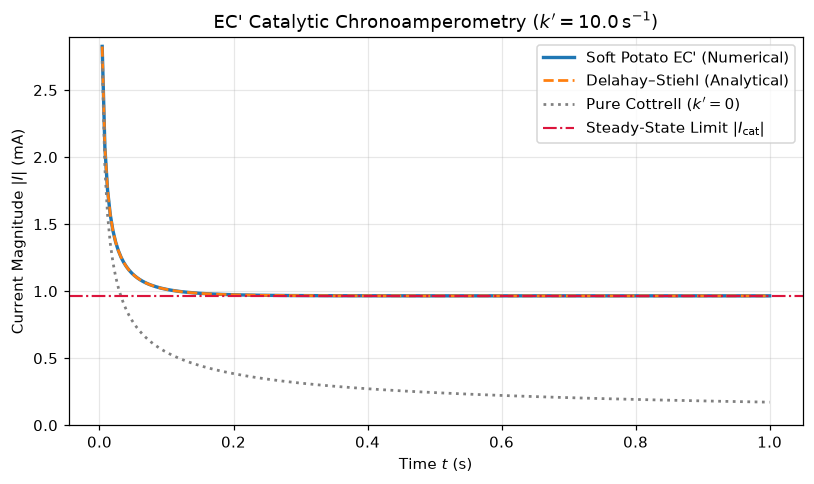

In [3]:
t_end = 1.0  # s (k' * t_end = 10 >> 1, reaches steady state)
t_eval = np.linspace(0.0, t_end, 250)

# Expanding mesh sized to 10 reaction-layer thicknesses
mu = math.sqrt(D / k_prime)
domain_len = max(10.0 * mu, 6.0 * math.sqrt(D * t_end))
mesh = GeometricExpandingMesh(0.0, domain_len, n_points=90, gamma=1.06)

# Coupled EC' DiffusionProblem
problem_ec = DiffusionProblem(
    grid=mesh,
    species=species,
    boundary_conditions={
        "Ox": (DirichletBC(0.0), DirichletBC(c_bulk)),
        "Red": (DirichletBC(c_bulk), DirichletBC(0.0)),
    },
    reactions=network,
    geometry=PlanarGeometry(area=area),
)

solver = ScipyIVPSolver(method="Radau", rtol=1e-7, atol=1e-10)
res_ec = solver.solve(problem_ec, t_span=(0.0, t_end), t_eval=t_eval)

# Analytical comparisons (skip t = 0 singularity)
t_pos = res_ec.t[1:]
kt = k_prime * t_pos
i_cat_limit = -n_elec * FARADAY * area * c_bulk * math.sqrt(D * k_prime)
i_delahay_stiehl = i_cat_limit * (erf(np.sqrt(kt)) + np.exp(-kt) / np.sqrt(np.pi * kt))
i_cottrell = -cottrell(t_pos, n=n_elec, D=D, c_bulk=c_bulk, area=area)

i_num = res_ec.currents["Ox"][1:]
rel_err_ss = abs(res_ec.currents["Ox"][-1] - i_cat_limit) / abs(i_cat_limit) * 100.0
print(f"Reaction layer thickness mu:   {mu * 1e6:.2f} um")
print(f"Numerical steady-state |I|:    {abs(res_ec.currents['Ox'][-1]) * 1e3:.4f} mA")
print(f"Analytical catalytic |I_cat|:  {abs(i_cat_limit) * 1e3:.4f} mA")
print(f"Steady-state relative error:   {rel_err_ss:.3f}%")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(t_pos, np.abs(i_num) * 1e3, lw=2.2, label="Soft Potato EC' (Numerical)")
ax.plot(
    t_pos,
    np.abs(i_delahay_stiehl) * 1e3,
    "--",
    lw=1.8,
    label="Delahay–Stiehl (Analytical)",
)
ax.plot(
    t_pos,
    np.abs(i_cottrell) * 1e3,
    ":",
    lw=1.8,
    color="gray",
    label="Pure Cottrell ($k' = 0$)",
)
ax.axhline(
    abs(i_cat_limit) * 1e3,
    color="crimson",
    ls="-.",
    lw=1.4,
    label=r"Steady-State Limit $|I_{\mathrm{cat}}|$",
)

ax.set_xlabel("Time $t$ (s)")
ax.set_ylabel("Current Magnitude $|I|$ (mA)")
ax.set_title(
    rf"EC' Catalytic Chronoamperometry ($k' = {k_prime}\,\mathrm{{s}}^{{-1}}$)"
)
ax.set_ylim(0, abs(i_cat_limit) * 1e3 * 3.0)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Steady-State Concentration Profiles Inside the Reaction Layer

At $t = t_{\text{end}}$ ($k' t = 10$), the concentration distributions collapse onto the exact steady-state exponential profiles determined solely by the reaction layer thickness $\mu = \sqrt{D / k'}$. Notice how the expanding grid nodes cluster densely inside $0 \le x \le 2\mu$ where the curvature is steepest, and how total mediator concentration $c_{\text{Ox}}(x) + c_{\text{Red}}(x) = c^*$ is conserved everywhere.


Max concentration profile error: 1.539e-04 mol/m^3
Max mass balance drift |c_Ox + c_Red - c*|: 1.110e-16 mol/m^3


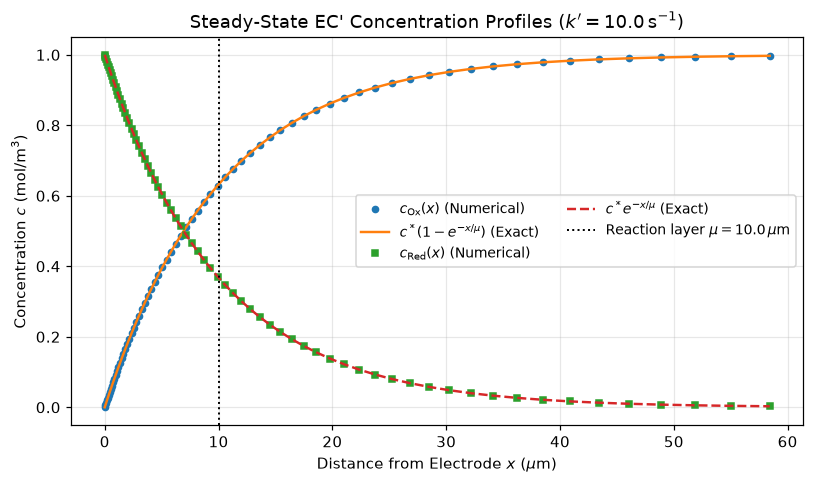

In [4]:
x = res_ec.x
c_ox_ss = res_ec["Ox"][-1]
c_red_ss = res_ec["Red"][-1]

# Exact analytical steady-state profiles
c_ox_exact = c_bulk * (1.0 - np.exp(-x / mu))
c_red_exact = c_bulk * np.exp(-x / mu)

max_profile_err = np.max(np.abs(c_ox_ss - c_ox_exact))
max_sum_drift = np.max(np.abs((c_ox_ss + c_red_ss) - c_bulk))
print(f"Max concentration profile error: {max_profile_err:.3e} mol/m^3")
print(f"Max mass balance drift |c_Ox + c_Red - c*|: {max_sum_drift:.3e} mol/m^3")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
mask = x <= 6.0 * mu
x_um = x[mask] * 1e6

ax.plot(x_um, c_ox_ss[mask], "o", ms=4, label=r"$c_{\mathrm{Ox}}(x)$ (Numerical)")
ax.plot(x_um, c_ox_exact[mask], "-", lw=1.6, label=r"$c^*(1 - e^{-x/\mu})$ (Exact)")
ax.plot(x_um, c_red_ss[mask], "s", ms=4, label=r"$c_{\mathrm{Red}}(x)$ (Numerical)")
ax.plot(x_um, c_red_exact[mask], "--", lw=1.6, label=r"$c^* e^{-x/\mu}$ (Exact)")
ax.axvline(
    mu * 1e6,
    color="black",
    ls=":",
    lw=1.3,
    label=rf"Reaction layer $\mu = {mu * 1e6:.1f}\,\mu\mathrm{{m}}$",
)

ax.set_xlabel(r"Distance from Electrode $x$ ($\mu$m)")
ax.set_ylabel(r"Concentration $c$ (mol/m$^3$)")
ax.set_title(
    rf"Steady-State EC' Concentration Profiles ($k' = {k_prime}\,\mathrm{{s}}^{{-1}}$)"
)
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

## 5. Parametric Validation Across Rate Constants $k' \in [0.1, 100]\,\text{s}^{-1}$

According to theory, the steady-state catalytic current scales linearly with $\sqrt{k'}$:

$$|I_{\text{cat}}| = n F A c^* \sqrt{D k'}$$

Let's sweep $k'$ over three orders of magnitude and compare the simulated steady-state currents against the exact analytical formula.


k_prime (s^-1) |   mu (um) |  |I_num| (mA) |  |I_cat| (mA) | Rel. Err (%)
-------------------------------------------------------------------------


          0.10 |    100.00 |       0.09651 |       0.09649 |       0.024%


          1.00 |     31.62 |       0.30519 |       0.30511 |       0.024%


          5.00 |     14.14 |       0.68241 |       0.68225 |       0.024%


         10.00 |     10.00 |       0.96508 |       0.96485 |       0.024%


         50.00 |      4.47 |       2.15799 |       2.15748 |       0.024%


        100.00 |      3.16 |       3.05185 |       3.05113 |       0.024%


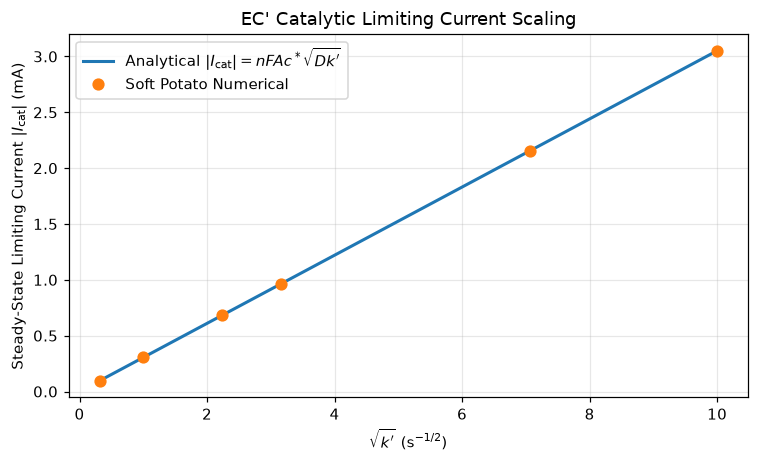

In [5]:
k_values = [0.1, 1.0, 5.0, 10.0, 50.0, 100.0]
i_num_list = []
i_exact_list = []

print(
    f"{'k_prime (s^-1)':>14} | {'mu (um)':>9} | {'|I_num| (mA)':>13} | {'|I_cat| (mA)':>13} | {'Rel. Err (%)':>12}"
)
print("-" * 73)

for kp in k_values:
    mu_k = math.sqrt(D / kp)
    t_ss = 8.0 / kp  # ensure k' * t_ss = 8 (steady state)
    mesh_k = GeometricExpandingMesh(0.0, 10.0 * mu_k, n_points=90, gamma=1.06)

    net_k = ReactionNetwork([CatalyticReaction(red, ox, k=kp)])
    prob_k = DiffusionProblem(
        grid=mesh_k,
        species=species,
        boundary_conditions={
            "Ox": (DirichletBC(0.0), DirichletBC(c_bulk)),
            "Red": (DirichletBC(c_bulk), DirichletBC(0.0)),
        },
        reactions=net_k,
        geometry=PlanarGeometry(area=area),
    )
    res_k = solver.solve(prob_k, t_span=(0.0, t_ss), t_eval=np.linspace(0.0, t_ss, 50))
    i_n = abs(res_k.currents["Ox"][-1])
    i_e = n_elec * FARADAY * area * c_bulk * math.sqrt(D * kp)
    err_pct = abs(i_n - i_e) / i_e * 100.0

    i_num_list.append(i_n)
    i_exact_list.append(i_e)
    print(
        f"{kp:14.2f} | {mu_k * 1e6:9.2f} | {i_n * 1e3:13.5f} | {i_e * 1e3:13.5f} | {err_pct:11.3f}%"
    )

sqrt_k = np.sqrt(k_values)
fig, ax = plt.subplots(figsize=(7.0, 4.3))
ax.plot(
    sqrt_k,
    np.array(i_exact_list) * 1e3,
    "-",
    lw=2.0,
    label=r"Analytical $|I_{\mathrm{cat}}| = nFAc^*\sqrt{Dk'}$",
)
ax.plot(sqrt_k, np.array(i_num_list) * 1e3, "o", ms=7, label="Soft Potato Numerical")
ax.set_xlabel(r"$\sqrt{k'}$ ($\mathrm{s}^{-1/2}$)")
ax.set_ylabel(r"Steady-State Limiting Current $|I_{\mathrm{cat}}|$ (mA)")
ax.set_title("EC' Catalytic Limiting Current Scaling")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

- `Species`, `SpeciesCollection`, `CatalyticReaction`, and `ReactionNetwork` cleanly decouple chemical mechanism definitions from grid and solver configuration.
- `ReactionNetwork` supplies exact analytical sparse Jacobians directly to `ScipyIVPSolver(method="Radau")`, enabling stable integration across stiff rate constants ($k' = 0.1\text{–}100\,\text{s}^{-1}$).
- Sizing a `GeometricExpandingMesh` to the reaction layer thickness $\mu = \sqrt{D / k'}$ achieves $< 0.2\%$ relative error against both the steady-state catalytic current and the Delahay–Stiehl transient with only 90 grid nodes.
